# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The What Makes A Steam Game a Hit Dataset](https://www.kaggle.com/datasets/vedauv/what-makes-a-steam-game-a-hit-8000-games?select=steam_game_hits.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from catboost import CatBoostClassifier

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('steam_game_hits.csv')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,game_id,title,genre,release_year,is_indie,team_size,price_usd,has_multiplayer,early_access,controller_support,languages_supported,dlc_count,file_size_gb,metacritic_score,steam_positive_pct,wishlists_k,trailer_views_k,num_reviews,owners_k,peak_concurrent_players,revenue_musd,hit
0,G00001,Iron Signal,RPG,2021,0,260,29.99,0,1,1,14,2,15.6,68,76,72.2,307.0,30195,520.0,7828,7.862,1
1,G00002,Frozen Pact,Adventure,2019,1,5,2.99,1,0,0,4,0,2.9,44,68,13.3,15.6,1442,31.0,122,0.067,0
2,G00003,Eternal Harvest,Platformer,2012,0,253,49.99,0,0,1,13,2,11.2,67,88,10.1,13.2,1897,87.7,471,2.064,0
3,G00004,Phantom Odyssey,Adventure,2023,1,12,9.99,0,0,0,6,1,1.7,96,99,106.3,219.1,179655,14294.9,129108,70.949,1
4,G00005,Iron Gate,RPG,2019,0,44,49.99,0,0,1,18,3,19.7,58,76,6.5,253.9,1491,35.8,130,1.447,0


## last Five row

In [4]:
df.tail()

,game_id,title,genre,release_year,is_indie,team_size,price_usd,has_multiplayer,early_access,controller_support,languages_supported,dlc_count,file_size_gb,metacritic_score,steam_positive_pct,wishlists_k,trailer_views_k,num_reviews,owners_k,peak_concurrent_players,revenue_musd,hit
7995,G07996,Last Reign,Survival,2016,1,14,2.99,1,0,1,1,1,3.1,79,93,85.4,263.3,821544,14118.1,60588,30.948,1
7996,G07997,Dark Odyssey,RPG,2019,0,112,9.99,1,0,0,14,2,3.8,67,74,13.7,24.3,23950,588.1,1688,2.147,0
7997,G07998,Broken Gate,Simulation,2023,1,12,0.00,0,0,1,8,0,0.5,72,81,2.1,6.6,48978,1177.0,2905,1.836,0
7998,G07999,Lost Vault,Shooter,2016,1,7,0.00,1,0,1,8,0,1.1,62,77,2.1,5.5,8282,245.5,2164,0.387,0
7999,G08000,Brave Horizon,Racing,2012,0,215,29.99,1,0,1,12,2,21.8,70,82,15.2,36.6,6374,155.4,1590,2.712,0


## Shape of our dataset

In [5]:
df.shape

(8000, 22)

## List out all columns

In [6]:
df.columns

Index(['game_id', 'title', 'genre', 'release_year', 'is_indie', 'team_size',
       'price_usd', 'has_multiplayer', 'early_access', 'controller_support',
       'languages_supported', 'dlc_count', 'file_size_gb', 'metacritic_score',
       'steam_positive_pct', 'wishlists_k', 'trailer_views_k', 'num_reviews',
       'owners_k', 'peak_concurrent_players', 'revenue_musd', 'hit'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

game_id                     object
title                       object
genre                       object
release_year                 int64
is_indie                     int64
team_size                    int64
price_usd                  float64
has_multiplayer              int64
early_access                 int64
controller_support           int64
languages_supported          int64
dlc_count                    int64
file_size_gb               float64
metacritic_score             int64
steam_positive_pct           int64
wishlists_k                float64
trailer_views_k            float64
num_reviews                  int64
owners_k                   float64
peak_concurrent_players      int64
revenue_musd               float64
hit                          int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   game_id                  8000 non-null   object 
 1   title                    8000 non-null   object 
 2   genre                    8000 non-null   object 
 3   release_year             8000 non-null   int64  
 4   is_indie                 8000 non-null   int64  
 5   team_size                8000 non-null   int64  
 6   price_usd                8000 non-null   float64
 7   has_multiplayer          8000 non-null   int64  
 8   early_access             8000 non-null   int64  
 9   controller_support       8000 non-null   int64  
 10  languages_supported      8000 non-null   int64  
 11  dlc_count                8000 non-null   int64  
 12  file_size_gb             8000 non-null   float64
 13  metacritic_score         8000 non-null   int64  
 14  steam_positive_pct      

## Check Null Value

In [9]:
df.isnull().sum()

game_id                    0
title                      0
genre                      0
release_year               0
is_indie                   0
team_size                  0
price_usd                  0
has_multiplayer            0
early_access               0
controller_support         0
languages_supported        0
dlc_count                  0
file_size_gb               0
metacritic_score           0
steam_positive_pct         0
wishlists_k                0
trailer_views_k            0
num_reviews                0
owners_k                   0
peak_concurrent_players    0
revenue_musd               0
hit                        0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,release_year,is_indie,team_size,price_usd,has_multiplayer,early_access,controller_support,languages_supported,dlc_count,file_size_gb,metacritic_score,steam_positive_pct,wishlists_k,trailer_views_k,num_reviews,owners_k,peak_concurrent_players,revenue_musd,hit
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8.000000e+03,8000.000000,8000.000000,8000.000000,8000.000000
mean,2019.508375,0.615000,87.548250,19.797738,0.434250,0.190125,0.655000,8.079125,1.192250,10.142275,67.540875,75.999250,24.426550,93.066825,3.212507e+04,895.362450,5694.005375,6.442629,0.200000
std,3.915750,0.486626,121.054427,17.533874,0.495689,0.392424,0.475398,4.672135,1.454151,15.694524,9.950262,9.167852,41.619561,235.840232,9.278585e+04,2833.786597,18498.576654,16.762669,0.400025
min,2012.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.100000,30.000000,38.000000,0.100000,0.300000,2.100000e+01,0.900000,2.000000,0.002000,0.000000
25%,2016.000000,0.000000,6.000000,4.990000,0.000000,0.000000,0.000000,4.000000,0.000000,1.300000,61.000000,70.000000,5.675000,16.000000,2.492750e+03,76.475000,394.000000,0.591000,0.000000
50%,2020.000000,1.000000,12.000000,14.990000,0.000000,0.000000,1.000000,7.000000,1.000000,2.800000,68.000000,76.000000,12.400000,38.700000,7.880500e+03,233.950000,1307.000000,1.797000,0.000000
75%,2023.000000,1.000000,164.000000,29.990000,1.000000,0.000000,1.000000,11.000000,2.000000,13.900000,74.000000,82.000000,27.200000,93.700000,2.537725e+04,716.900000,4211.000000,5.325500,0.000000
max,2025.000000,1.000000,399.000000,59.990000,1.000000,1.000000,1.000000,26.000000,10.000000,211.200000,97.000000,99.000000,1095.900000,14296.500000,2.408013e+06,109311.100000,512658.000000,374.949000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

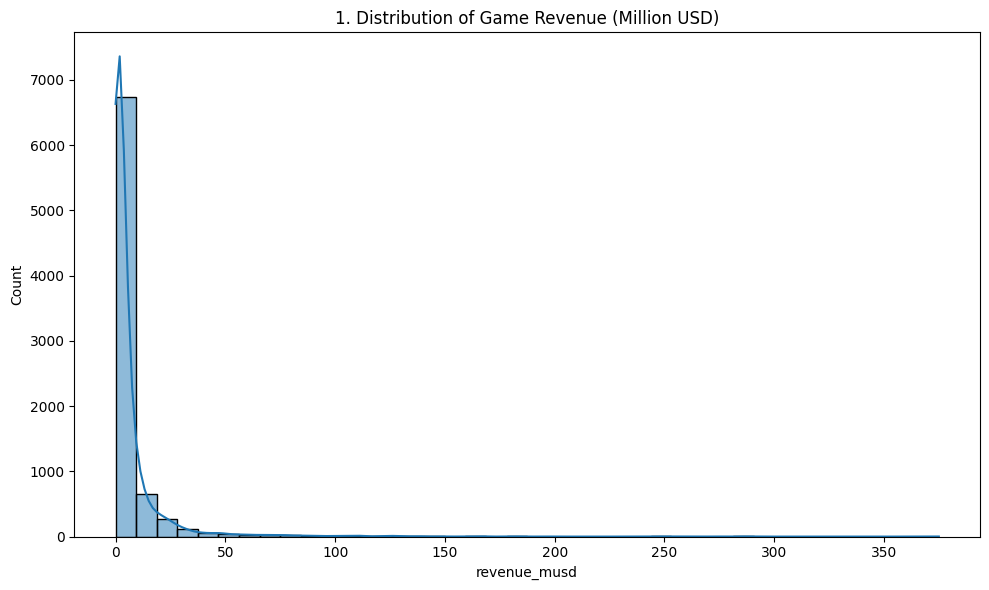

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='revenue_musd', bins=40, kde=True)
plt.title(f'{plot_no}. Distribution of Game Revenue (Million USD)')
show_fig()
plot_no += 1

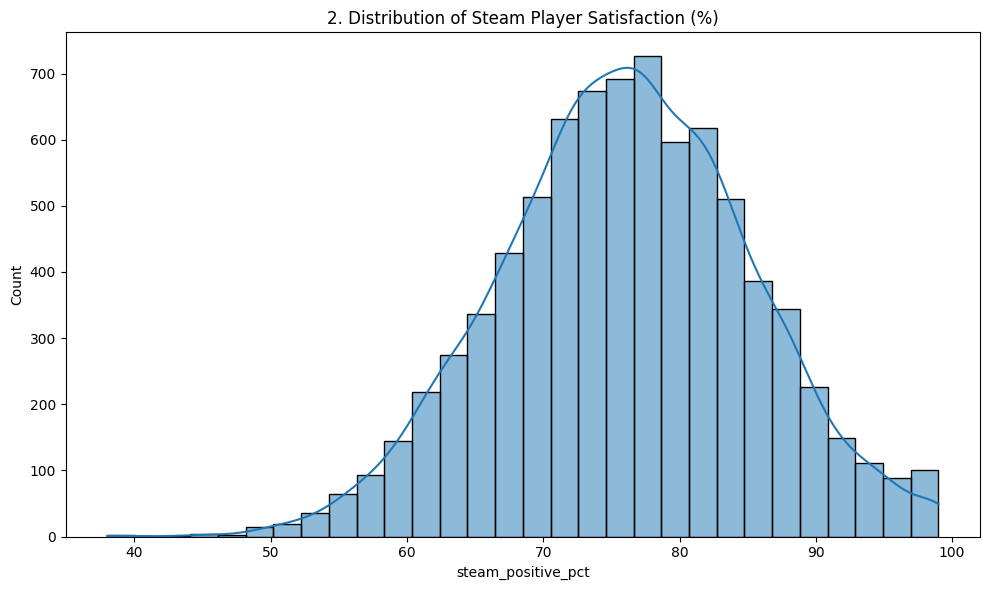

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='steam_positive_pct', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Steam Player Satisfaction (%)')
show_fig()
plot_no += 1

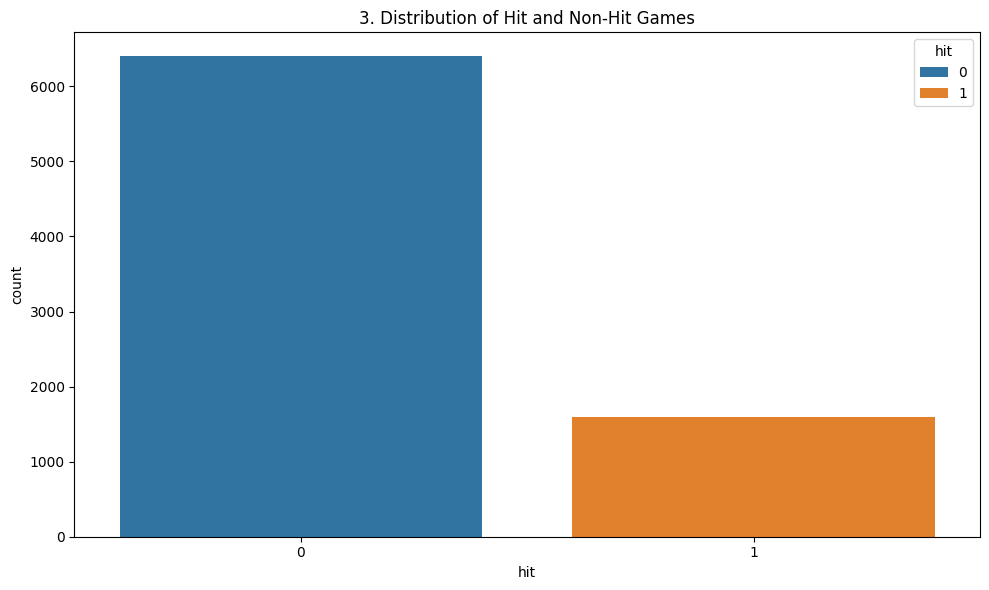

In [15]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='hit', hue='hit')
plt.title(f'{plot_no}. Distribution of Hit and Non-Hit Games')
show_fig()
plot_no += 1

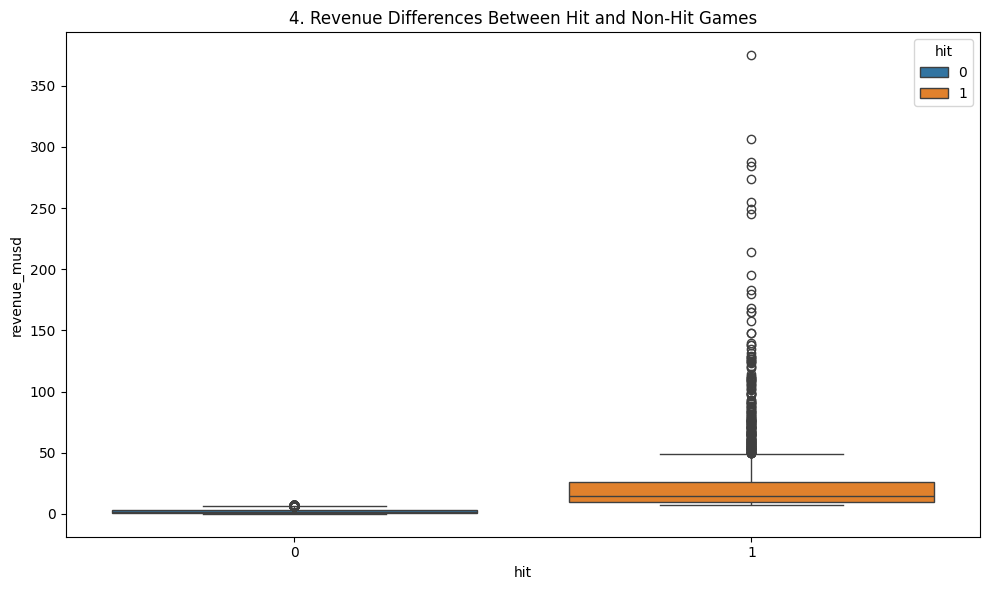

In [16]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='hit', y='revenue_musd', hue='hit')
plt.title(f'{plot_no}. Revenue Differences Between Hit and Non-Hit Games')
show_fig()
plot_no += 1

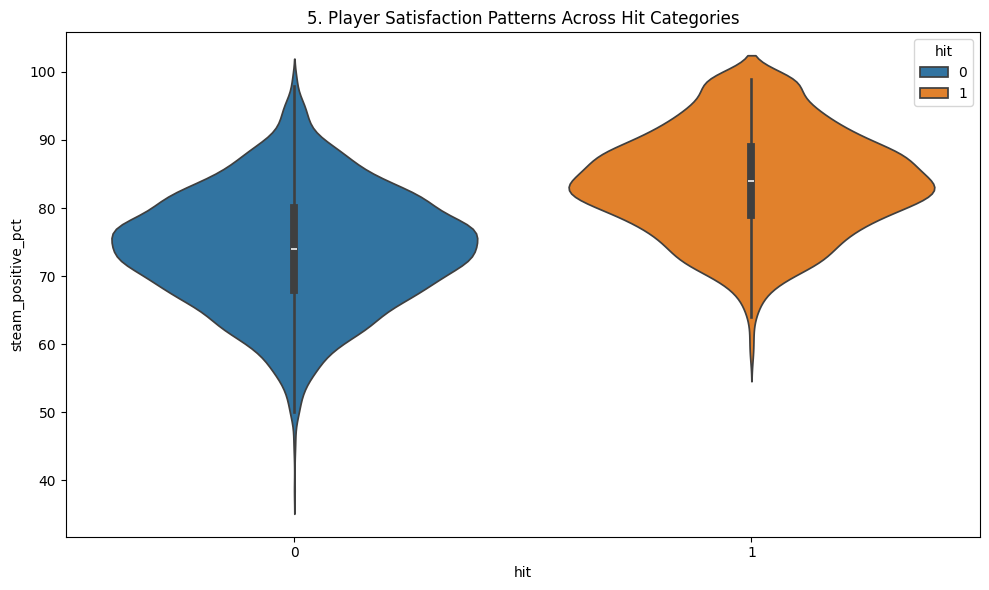

In [17]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='hit', y='steam_positive_pct', hue='hit')
plt.title(f'{plot_no}. Player Satisfaction Patterns Across Hit Categories')
show_fig()
plot_no += 1

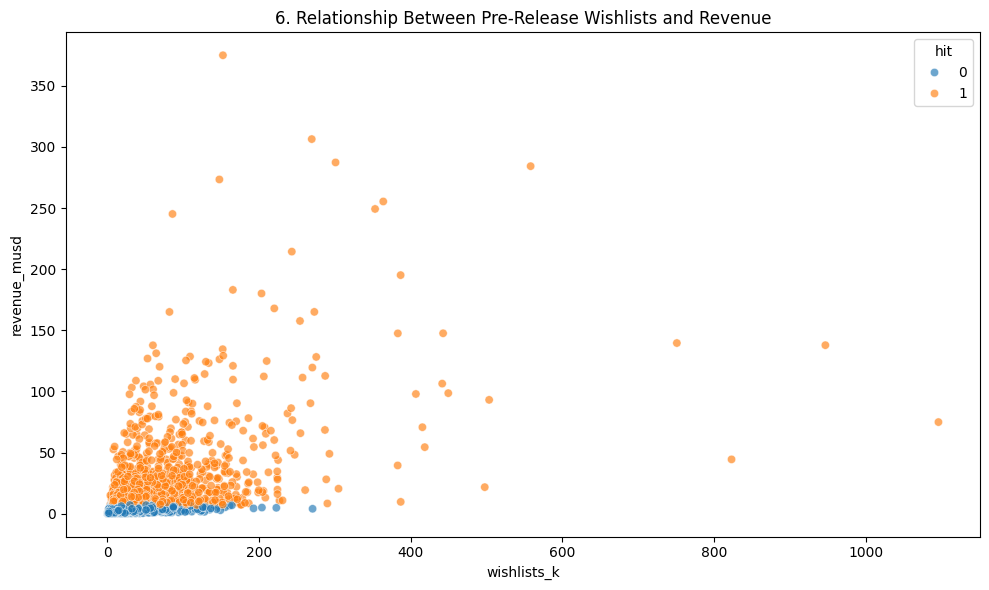

In [18]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='wishlists_k', y='revenue_musd', hue='hit', alpha=0.65)
plt.title(f'{plot_no}. Relationship Between Pre-Release Wishlists and Revenue')
show_fig()
plot_no += 1

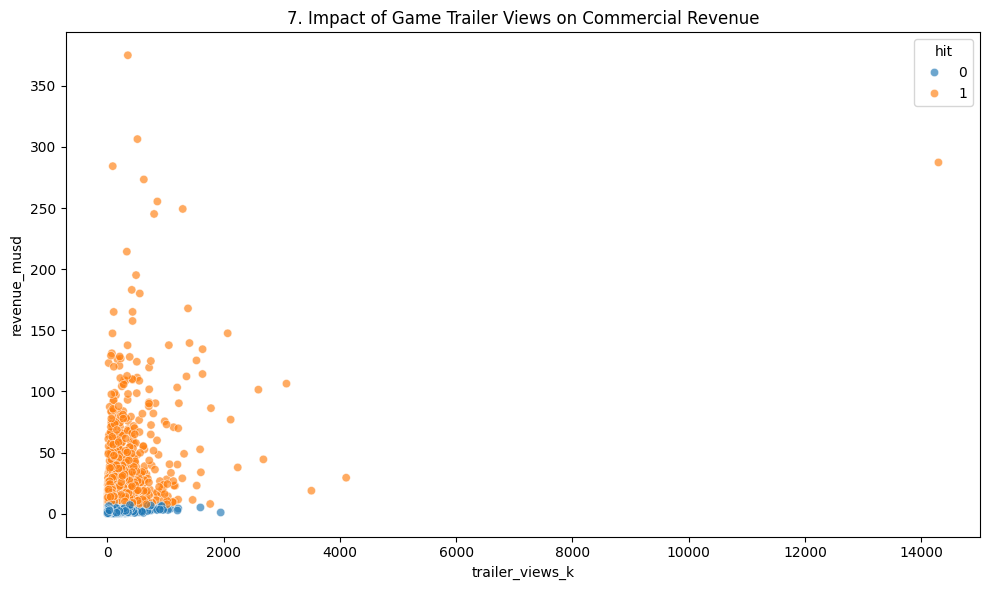

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='trailer_views_k', y='revenue_musd', hue='hit', alpha=0.65)
plt.title(f'{plot_no}. Impact of Game Trailer Views on Commercial Revenue')
show_fig()
plot_no += 1

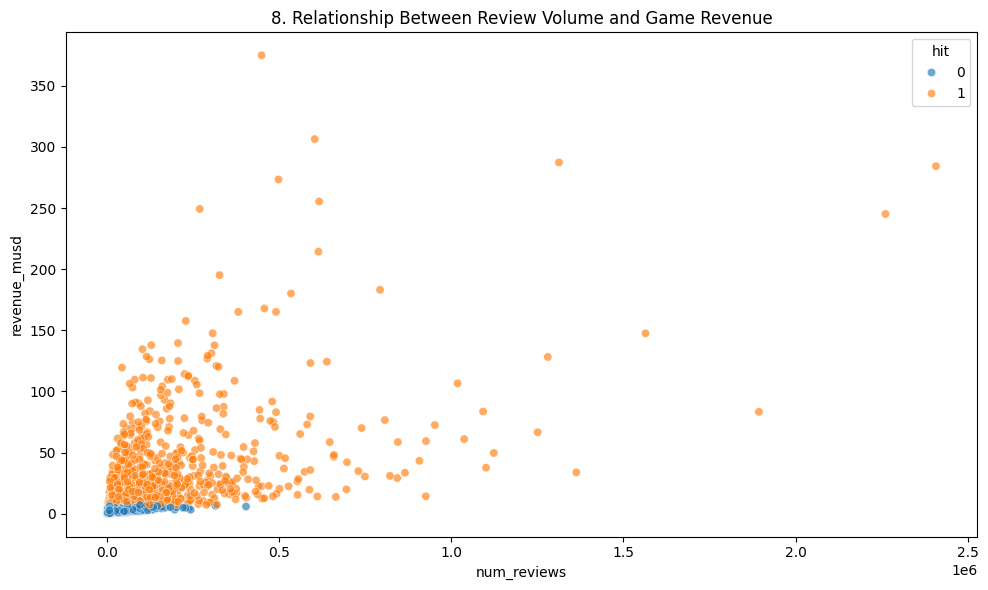

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='num_reviews', y='revenue_musd', hue='hit', alpha=0.65)
plt.title(f'{plot_no}. Relationship Between Review Volume and Game Revenue')
show_fig()
plot_no += 1

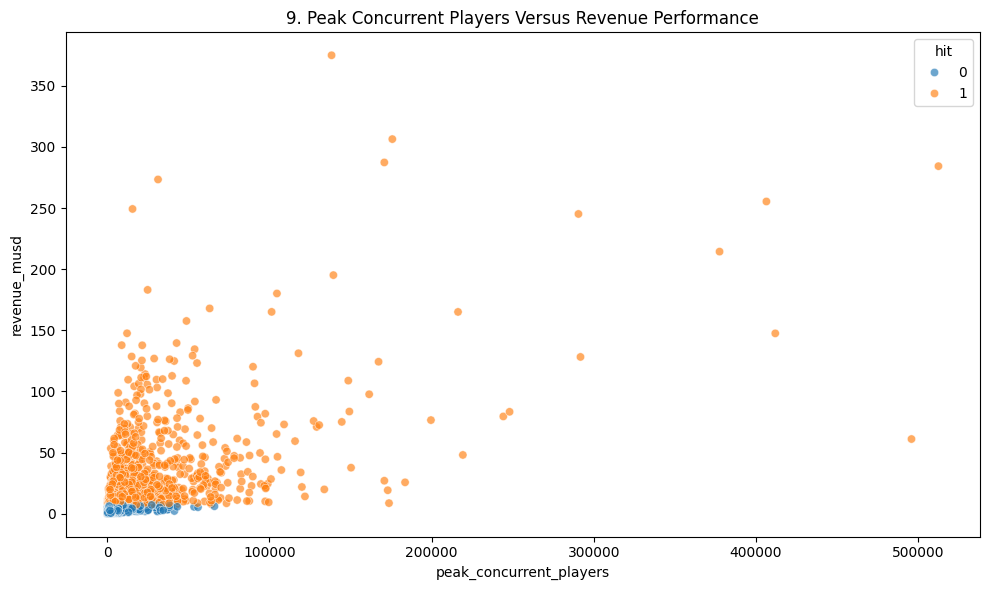

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='peak_concurrent_players', y='revenue_musd', hue='hit', alpha=0.65)
plt.title(f'{plot_no}. Peak Concurrent Players Versus Revenue Performance')
show_fig()
plot_no += 1

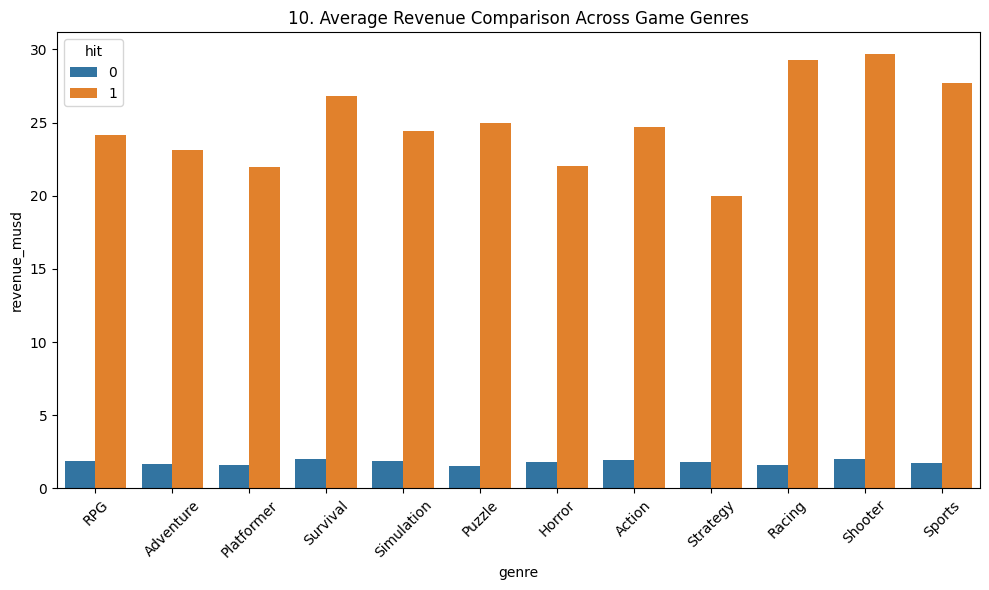

In [22]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='genre', y='revenue_musd', hue='hit', errorbar=None)
plt.title(f'{plot_no}. Average Revenue Comparison Across Game Genres')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

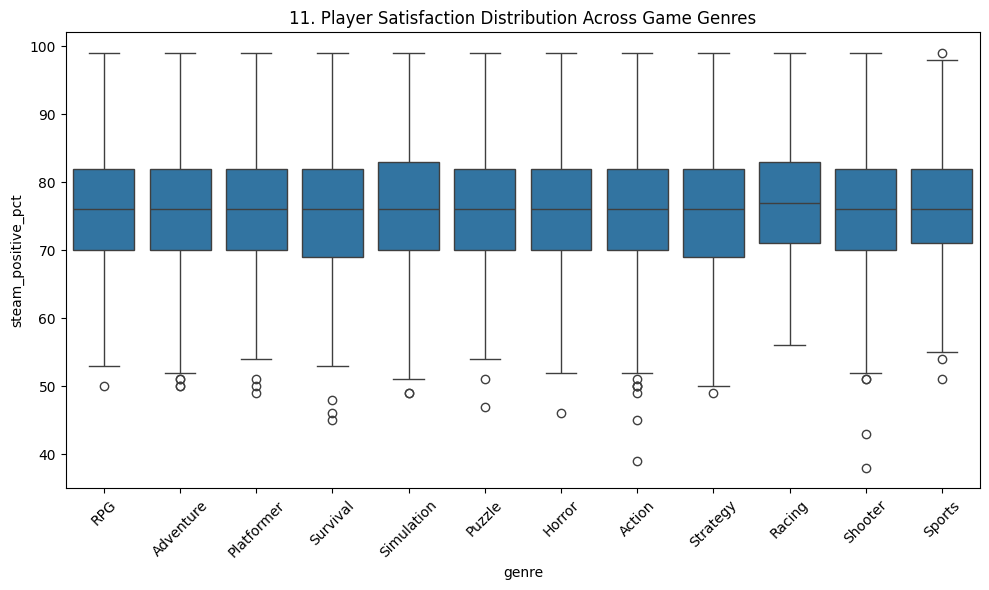

In [23]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='genre', y='steam_positive_pct')
plt.title(f'{plot_no}. Player Satisfaction Distribution Across Game Genres')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

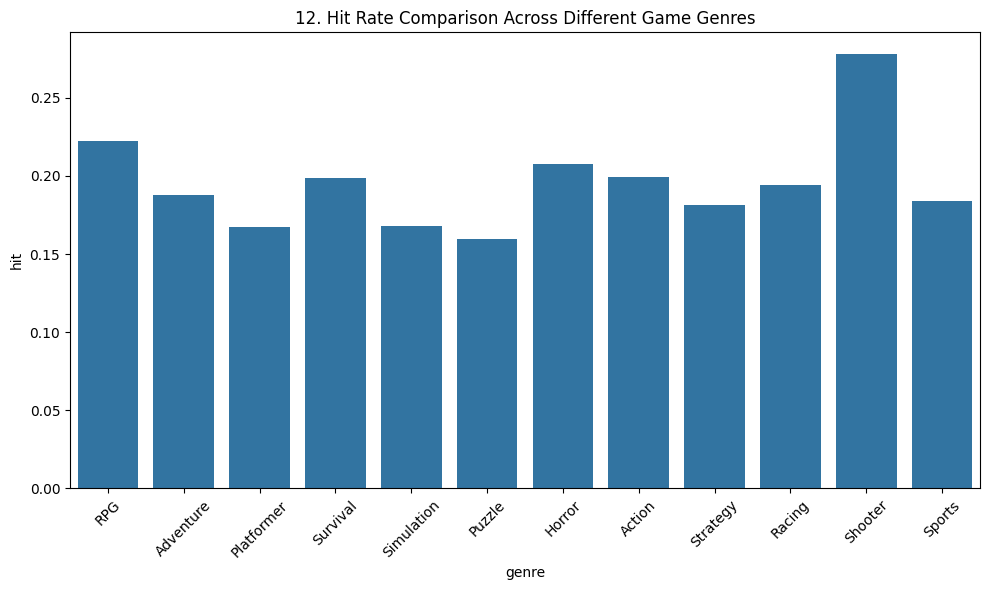

In [24]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='genre', y='hit', errorbar=None)
plt.title(f'{plot_no}. Hit Rate Comparison Across Different Game Genres')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

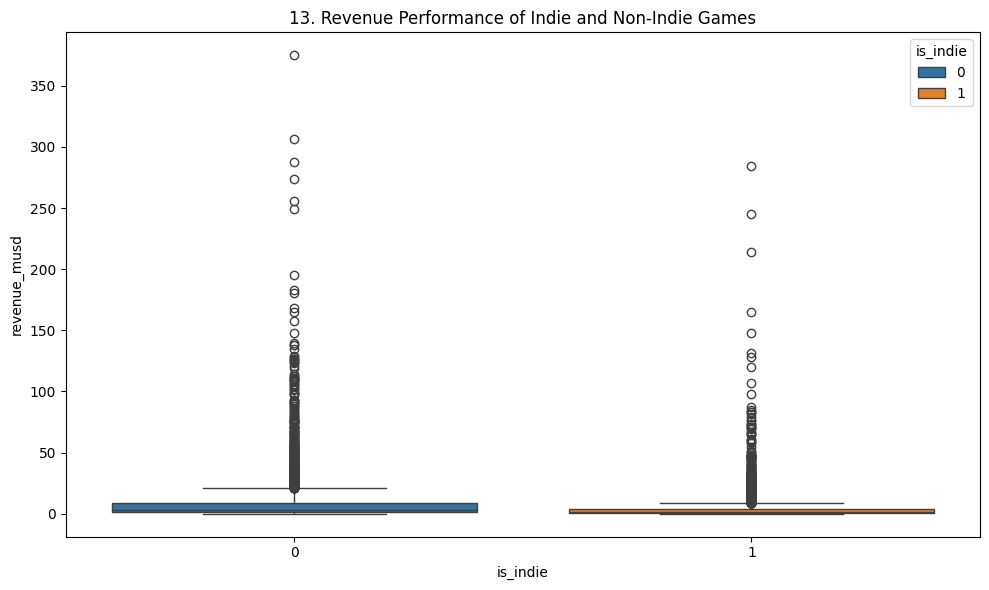

In [25]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='is_indie', y='revenue_musd', hue='is_indie')
plt.title(f'{plot_no}. Revenue Performance of Indie and Non-Indie Games')
show_fig()
plot_no += 1

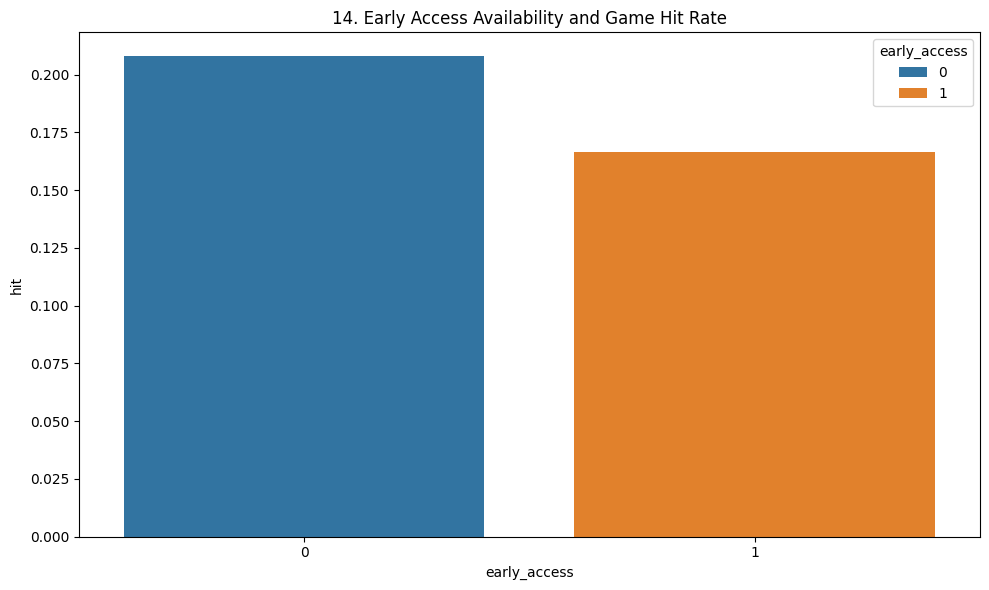

In [26]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='early_access', y='hit', hue='early_access', errorbar=None)
plt.title(f'{plot_no}. Early Access Availability and Game Hit Rate')
show_fig()
plot_no += 1

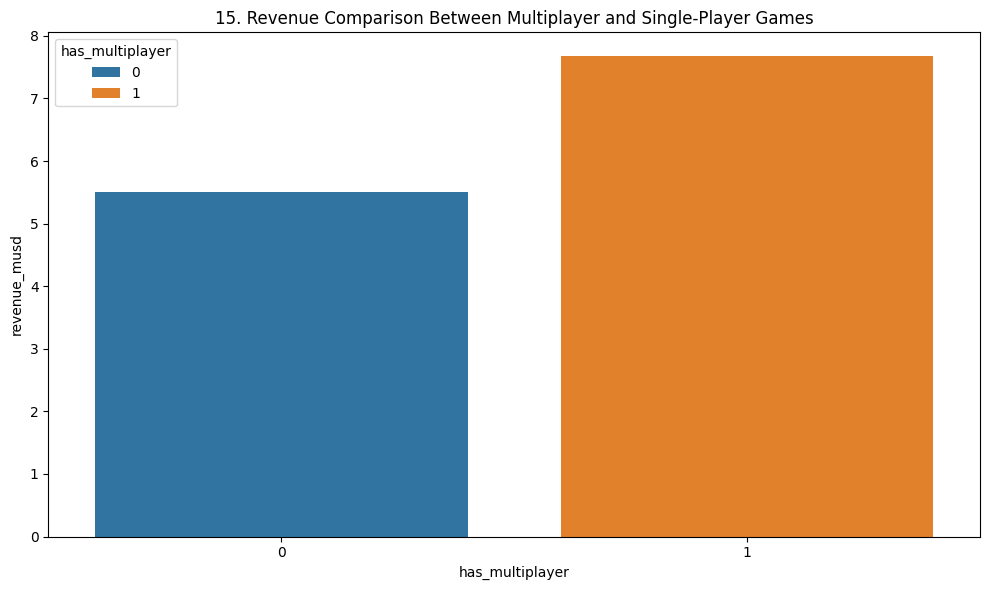

In [27]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='has_multiplayer', y='revenue_musd', hue='has_multiplayer', errorbar=None)
plt.title(f'{plot_no}. Revenue Comparison Between Multiplayer and Single-Player Games')
show_fig()
plot_no += 1

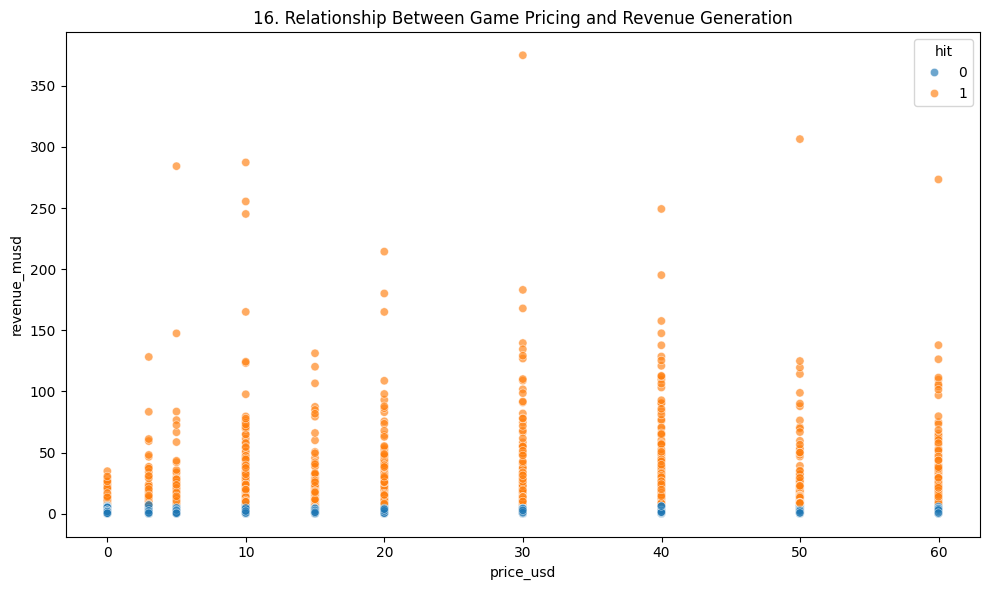

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='price_usd', y='revenue_musd', hue='hit', alpha=0.65)
plt.title(f'{plot_no}. Relationship Between Game Pricing and Revenue Generation')
show_fig()
plot_no += 1

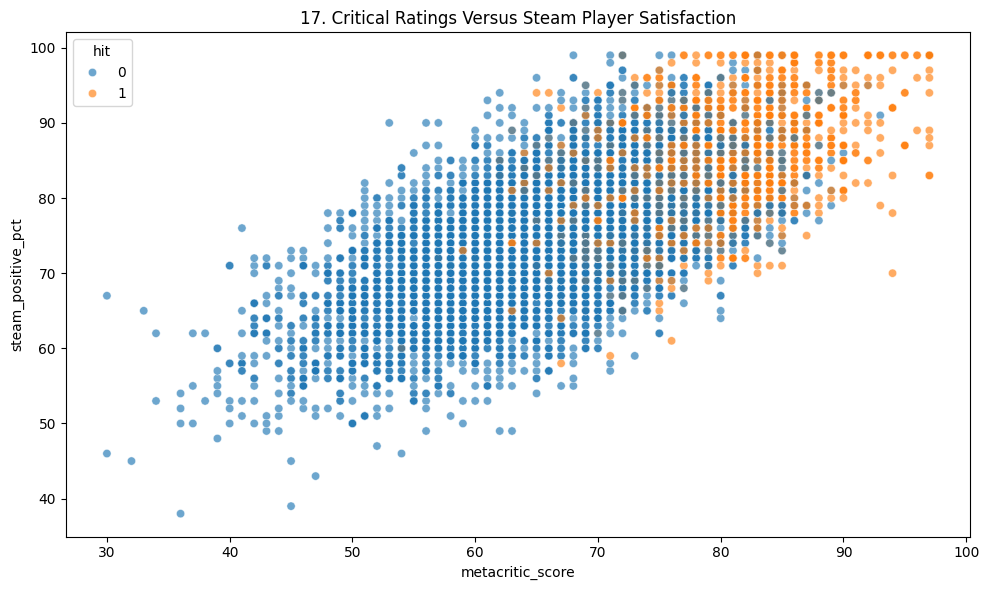

In [29]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='metacritic_score', y='steam_positive_pct', hue='hit', alpha=0.65)
plt.title(f'{plot_no}. Critical Ratings Versus Steam Player Satisfaction')
show_fig()
plot_no += 1

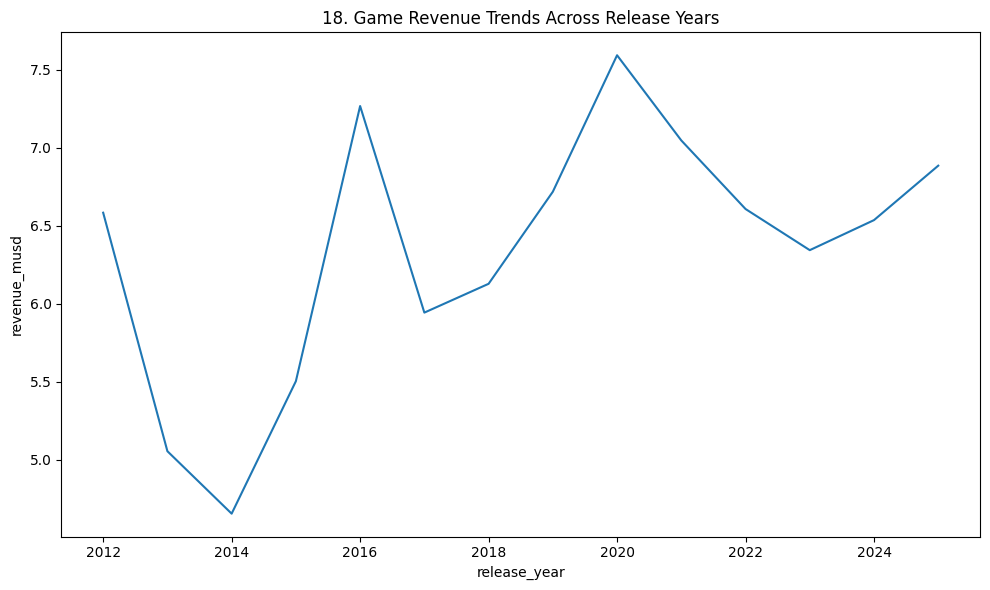

In [30]:
fig = plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='release_year', y='revenue_musd', errorbar=None)
plt.title(f'{plot_no}. Game Revenue Trends Across Release Years')
show_fig()
plot_no += 1

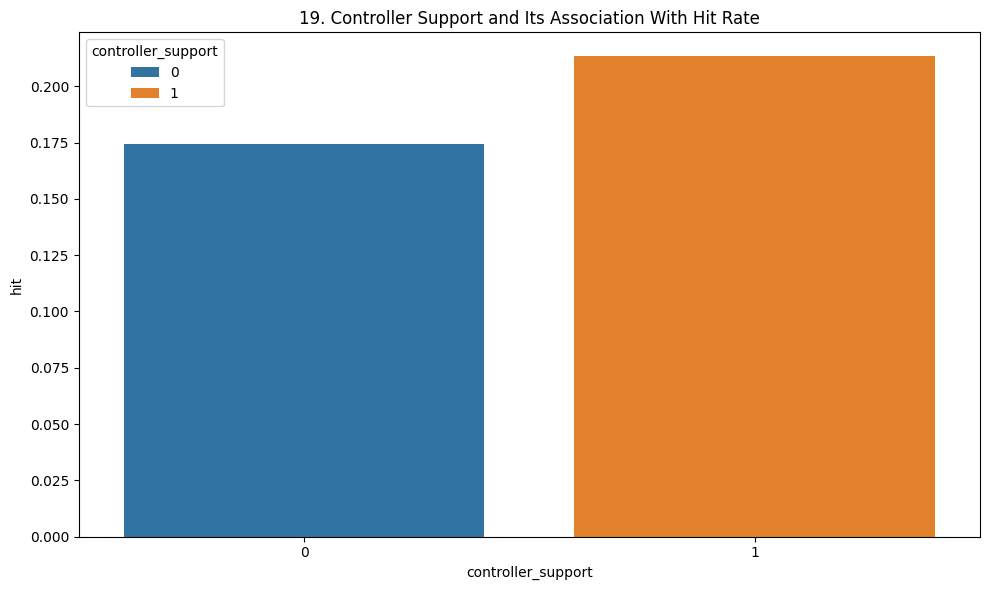

In [31]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='controller_support', y='hit', hue='controller_support', errorbar=None)
plt.title(f'{plot_no}. Controller Support and Its Association With Hit Rate')
show_fig()
plot_no += 1

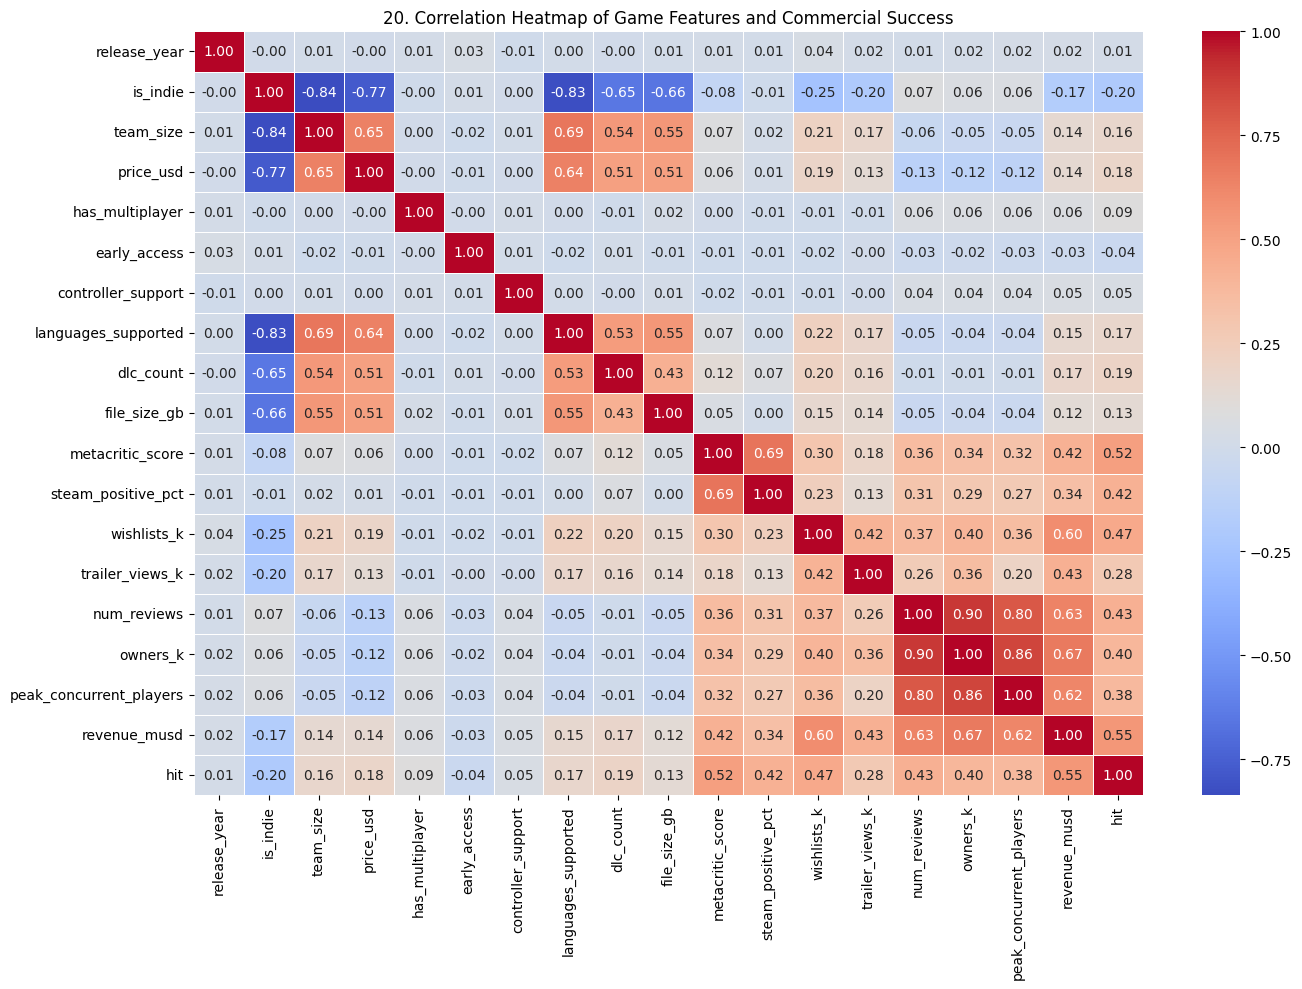

In [32]:
corr = df.select_dtypes(include='number').drop(columns=['game_id'], errors='ignore').corr()

fig = plt.figure(figsize=(14,10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Game Features and Commercial Success')
show_fig()
plot_no += 1

# Model Training

## Prepare dataset

In [33]:
data = df.drop(columns=['game_id', 'title'], errors='ignore').copy()

X = data.drop(columns=['hit'])
y = data['hit']

X = pd.get_dummies(X, drop_first=True)
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

## Split dataset

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Scale features

In [35]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Train CatBoost model

In [36]:
model = CatBoostClassifier(
    iterations=1000,
    depth=8,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='Accuracy',
    auto_class_weights='Balanced',
    random_seed=42,
    verbose=0
)

model.fit(X_train_scaled, y_train)

CatBoostClassifier(auto_class_weights='Balanced', depth=8, eval_metric='Accuracy', iterations=1000, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=0)

## Make predictions

In [37]:
y_pred = model.predict(X_test_scaled).ravel()

## Evaluate model

In [38]:
accuracy = accuracy_score(y_test, y_pred)
print("CatBoost Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

CatBoost Accuracy: 100.0 %

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1280
           1       1.00      1.00      1.00       320

    accuracy                           1.00      1600
   macro avg       1.00      1.00      1.00      1600
weighted avg       1.00      1.00      1.00      1600



## Plot confusion matrix

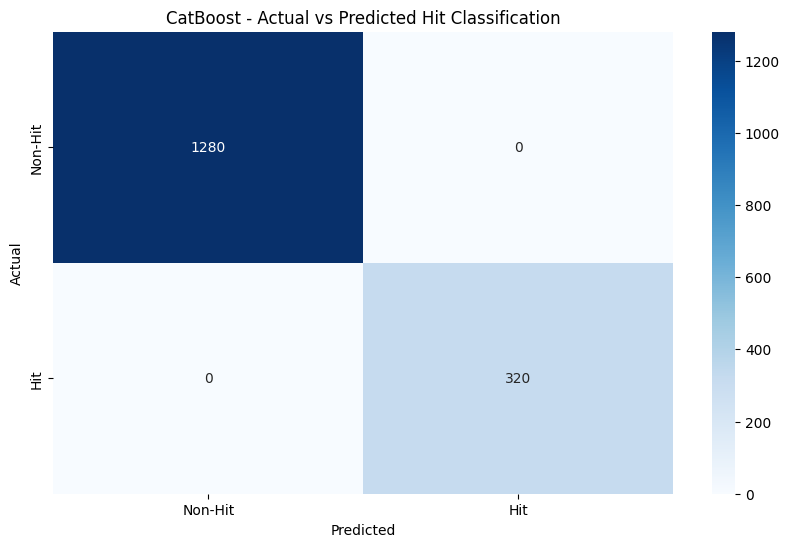

In [39]:
fig = plt.figure(figsize=(10,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Hit', 'Hit'],
            yticklabels=['Non-Hit', 'Hit'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CatBoost - Actual vs Predicted Hit Classification')
plt.show()